In [1]:
import sys, os
sys.path.insert(0, os.getcwd())

import pickle
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp

from train import (load_training_params, setup_training,
                   run_training_loop, plot_training_log)

In [2]:
# ── What to train ─────────────────────────────────────────────────────────────
train_task = 'harmonic'

# Frequency grid context: includes all task types the animal may encounter,
# so the network learns to encode across the full frequency range.
task_list  = ['pure', 'harmonic', 'wn']

# ── Training schedule ────────────────────────────────────────────────────────
n_steps       = 15000   # total training batches
k             = 100     # evaluate and save every k batches
seed          = 0
eval_with_noise = True  # if True, evaluation uses same noise as training

# ── Save location ────────────────────────────────────────────────────────────
RESULTS_DIR = Path(os.environ.get('TONE_RESULTS_DIR', 'results'))
save_dir = str(RESULTS_DIR / train_task) + '/'

In [3]:
state, cfg = setup_training(train_task, task_list, n_steps, k, seed, save_dir)

task_list : ['pure', 'harmonic', 'wn']
train_task: harmonic
n_freq=50  n_in=54 (freq+fixation+context)  n_rnn=128  alpha=0.100
pulse_dur=50ms  n_pulses=8  stim_dur=400ms  tdim=240 (2400ms)
save_dir  : C:\Users\zhixi\Documents\GitHub\tone_generalize\code\results\harmonic\harmonic_0_lr5e-05_bs128_noise0.5_nrnn128


In [4]:
state, log = run_training_loop(state, train_task, task_list, cfg, eval_with_noise=eval_with_noise)

step    100  loss=0.2351  hit=0.01  FA=0.01
step    200  loss=0.2229  hit=0.03  FA=0.03
step    300  loss=0.2200  hit=0.07  FA=0.04
step    400  loss=0.2046  hit=0.04  FA=0.07
step    500  loss=0.1940  hit=0.08  FA=0.13
step    600  loss=0.1783  hit=0.25  FA=0.20
step    700  loss=0.1675  hit=0.46  FA=0.24
step    800  loss=0.1384  hit=0.79  FA=0.40
step    900  loss=0.0957  hit=0.89  FA=0.23
step   1000  loss=0.0738  hit=0.80  FA=0.03
step   1100  loss=0.0641  hit=0.73  FA=0.02
step   1200  loss=0.0600  hit=0.76  FA=0.01
step   1300  loss=0.0535  hit=0.67  FA=0.00
step   1400  loss=0.0493  hit=0.75  FA=0.00
step   1500  loss=0.0433  hit=0.66  FA=0.00
step   1600  loss=0.0389  hit=0.66  FA=0.00
step   1700  loss=0.0408  hit=0.61  FA=0.00
step   1800  loss=0.0392  hit=0.68  FA=0.00
step   1900  loss=0.0360  hit=0.61  FA=0.00
step   2000  loss=0.0353  hit=0.72  FA=0.01
step   2100  loss=0.0331  hit=0.64  FA=0.00
step   2200  loss=0.0319  hit=0.72  FA=0.00
step   2300  loss=0.0295  hit=0.

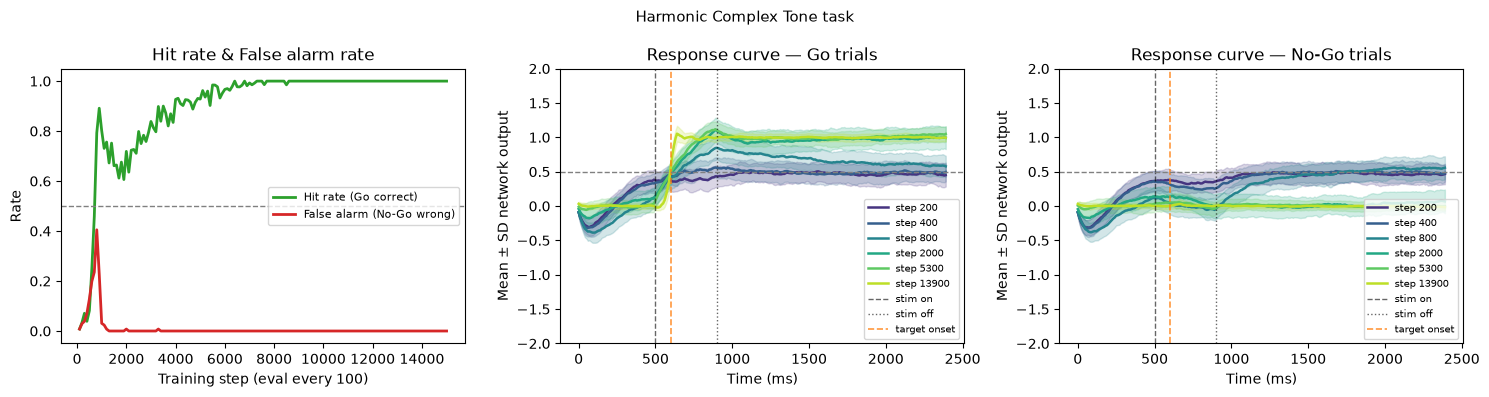

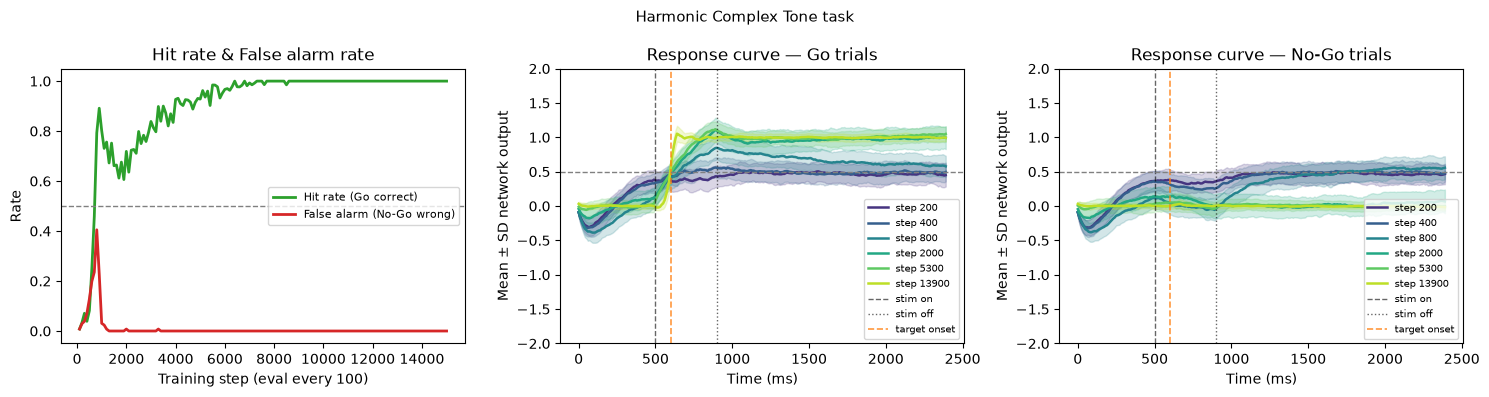

In [5]:
plot_training_log(cfg['save_path'], title='Harmonic Complex Tone task', last_snap_step=14000)